# Tutorial 1 — Camadas ao redor de um círculo

## 1. Importações

In [1]:
from pathlib import Path
import sys

# Importar o pacote local
project_root = Path.cwd()
if project_root.name == "tutorials":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import insert_contour, initialize_front, compute_normals, advance_front
from meshlab.utils import plot_mesh

## 2. Parâmetros

In [2]:
radius = 1.0
num_points = 64
height = 0.08
growth_rate = 1.15
additional_layers = 5
outer_radius = 3.5

## 3. Círculo

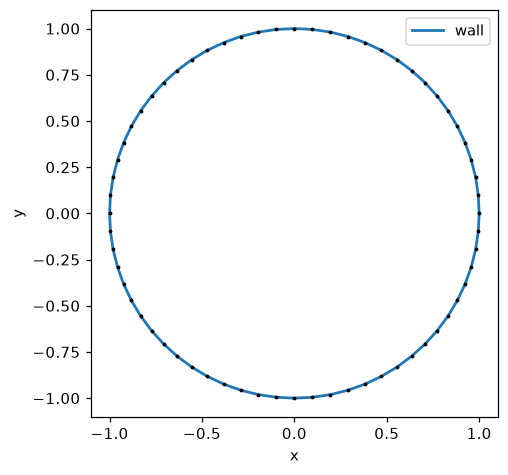

In [3]:
# Sentido anti-horário: normais para fora do corpo
angles = np.linspace(0.0, 2.0 * np.pi, num_points, endpoint=False)
points = radius * np.column_stack((np.cos(angles), np.sin(angles)))
points = np.vstack((points, points[0]))

circle = Contour("body", [Curve("wall", points)])
mesh = Mesh(dim=2)
insert_contour(mesh, circle)

plot_mesh(mesh);

## 4. Inicialização da frente

In [4]:
front = Front("body_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

## 5. Primeira camada

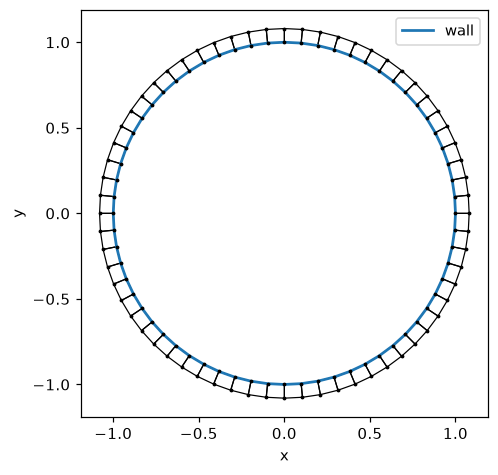

In [5]:
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

plot_mesh(mesh);

## 6. Segunda camada

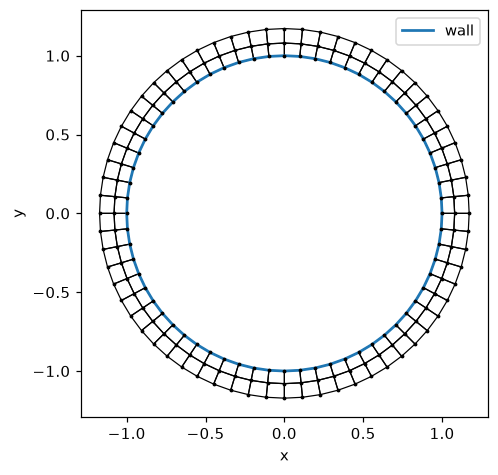

In [6]:
height *= growth_rate
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

plot_mesh(mesh);

## 7. Terceira camada

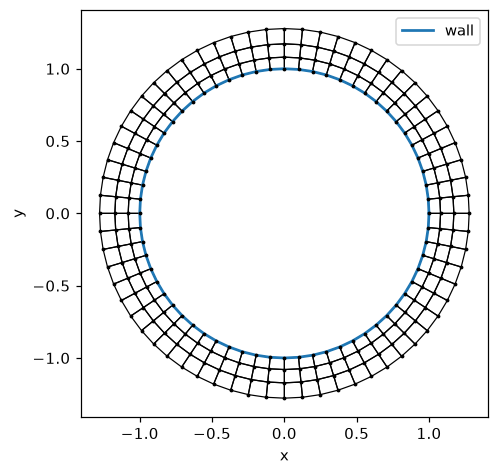

In [7]:
height *= growth_rate
normals = compute_normals(mesh, front, method="central")
advance_front(mesh, front, normals, height)

plot_mesh(mesh);

## 8. Camadas adicionais

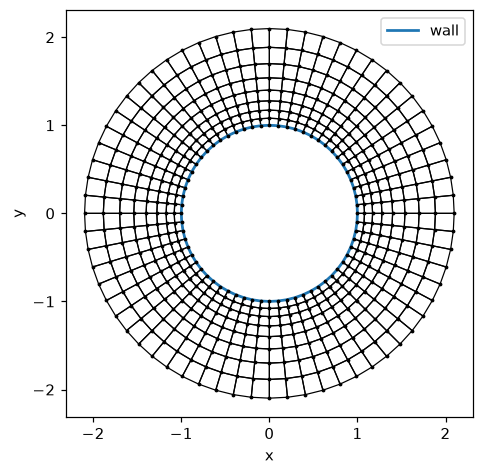

In [8]:
for _ in range(additional_layers):
    height *= growth_rate
    normals = compute_normals(mesh, front, method="central")
    advance_front(mesh, front, normals, height)

plot_mesh(mesh);

## 9. Domínio externo e visualização final

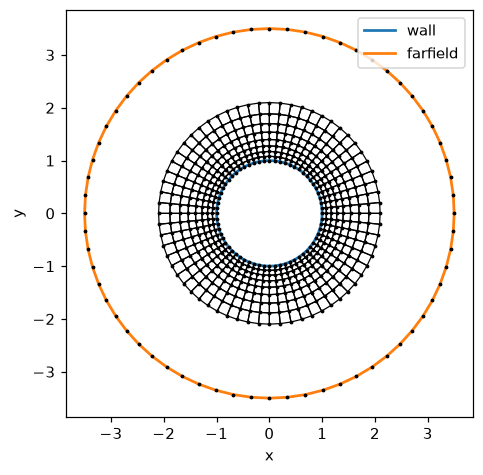

In [9]:
# Sentido horário: normal para o interior do domínio
outer_angles = np.linspace(0.0, -2.0 * np.pi, num_points, endpoint=False)
outer_points = outer_radius * np.column_stack((np.cos(outer_angles), np.sin(outer_angles)))
outer_points = np.vstack((outer_points, outer_points[0]))

outer_domain = Contour("outer_domain", [Curve("farfield", outer_points)])
insert_contour(mesh, outer_domain)

# A região entre as camadas e o domínio externo ainda não está malhada
plot_mesh(mesh);